# Lab 01 — Understanding Bayes' Theorem in Python
### Prior · Likelihood · Evidence (marginal) · Posterior

**Audience:** Final-year undergraduate / Master's / Engineering students · **Estimated duration:** 1 h 45 – 2 h 30 · **Hardware:** CPU only.

**Objectives.** By the end of this lab, you will be able to (1) identify the four terms in Bayes' theorem, (2) compute a posterior probability in a concrete example, (3) marginalize over several hypotheses, (4) update knowledge using multiple observations, and (5) connect Bayes' theorem to a continuous latent parameter.

**Lab workflow:** question → formula → Python calculation → visualization → interpretation → exercise.

> The scenarios are fictional and are intended solely for learning probability.


## 0. The forward problem and the inverse problem

The **forward model** answers: *What observation will I obtain if the hypothesis is true?*

$
H \longrightarrow Y,\qquad P(Y\mid H).
$

The **inverse problem** answers: *Which hypothesis is plausible after seeing the observation?*

$
Y \longrightarrow H,\qquad P(H\mid Y).
$

Bayes' theorem connects the two:

$
\boxed{P(H\mid Y)=\frac{P(Y\mid H)P(H)}{P(Y)}}.
$

| Term | Name | Role |
|---|---|---|
| $P(H)$      |**Prior** | Knowledge before the observation |
| $P(Y\mid H)$     | **Likelihood**  | Compatibility of the observation with the hypothesis |
| $P(Y)$ | **Evidence / marginal** | Total probability of the observation |
| $P(H\mid Y)$ | **Posterior** | Updated knowledge |

*Marginalization* for mutually exclusive and exhaustive hypotheses $H_1,\dots,H_K$:

$
P(Y)=\sum_{k=1}^{K}P(Y\mid H_k)P(H_k).
$

**Caution:** in general, $P(Y\mid H)\neq P(H\mid Y)$. The likelihood **is not** the posterior probability.


## 1. Imports — a self-contained notebook (no data downloads)


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.special import beta as beta_function, comb
from scipy.stats import beta as beta_dist, norm
from scipy.integrate import trapezoid

np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(42)
print('Environment ready:', np.__version__)

Environment ready: 2.1.3


## 2. Concrete example A — A quality-control test

A factory manufactures parts. A device signals $+$ when it detects a defective part.

- **Prior:** $P(D)=0.02$ (2% of parts are defective).
- **Sensitivity:** $P(+\mid D)=0.95$.
- **Specificity:** $P(-\mid \neg D)=0.90$, so $P(+\mid\neg D)=0.10$.

**Before calculating:** among the flagged parts, are most actually defective?


In [ ]:
prior_defect = 0.02
sensitivity = 0.95
specificity = 0.90
false_positive_rate = 1 - specificity

likelihood_pos_if_defect = sensitivity
likelihood_pos_if_ok = false_positive_rate

evidence_pos = (likelihood_pos_if_defect * prior_defect
                + likelihood_pos_if_ok * (1-prior_defect))
posterior_defect_if_pos = likelihood_pos_if_defect * prior_defect / evidence_pos

print(f'Prior P(D)              = {prior_defect:.2%}')
print(f'Likelihood P(+|D)       = {likelihood_pos_if_defect:.2%}')
print(f'Evidence P(+)           = {evidence_pos:.2%}')
print(f'Posterior P(D|+)        = {posterior_defect_if_pos:.2%}')
assert np.isclose(evidence_pos, 0.117)
assert np.isclose(posterior_defect_if_pos, 190/1170)

Prior P(D)              = 2.00%
Likelihood P(+|D)       = 95.00%
Evidence P(+)           = 11.70%
Posterior P(D|+)        = 16.24%


### 2.1 The same result using counts (10,000 parts)

Reasoning with frequencies makes the difference between **sensitivity and positive predictive value** visible.


In [ ]:
N = 10_000
n_defect = N * prior_defect
n_ok = N - n_defect
TP = n_defect * sensitivity
FN = n_defect * (1-sensitivity)
FP = n_ok * false_positive_rate
TN = n_ok * specificity

ct = pd.DataFrame({
    'Test +': [int(TP), int(FP)],
    'Test -': [int(FN), int(TN)]
}, index=['Defective', 'Conforming'])
display(ct)
print('Among positive tests:', f'{TP:.0f} true positives / {TP+FP:.0f} positives')
print('Fraction actually defective:', f'{TP/(TP+FP):.2%}')

,Test +,Test -
Defective,190,10
Conforming,979,8820


Among positive tests: 190 true positives / 1170 positives
Fraction actually defective: 16.24%


### 2.2 How the defect rate changes the result

Vary the **prior** while keeping the same test.


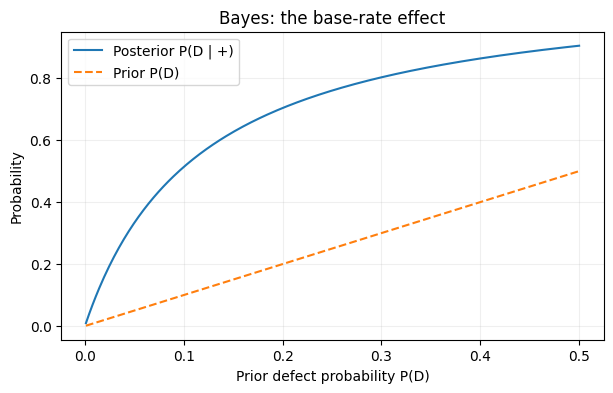

In [ ]:
def bayes_binary(prior, sens, spec):
    evidence = sens*prior + (1-spec)*(1-prior)
    posterior = sens*prior/evidence
    return evidence, posterior

priors = np.linspace(0.001, 0.5, 300)
post = np.array([bayes_binary(p, 0.95, 0.90)[1] for p in priors])

plt.figure(figsize=(7,4))
plt.plot(priors, post, label='Posterior P(D | +)')
plt.plot(priors, priors, linestyle='--', label='Prior P(D)')
plt.xlabel('Prior defect probability P(D)')
plt.ylabel('Probability')
plt.title('Bayes: the base-rate effect')
plt.grid(alpha=0.2)
plt.legend()
plt.show()

**Interpretation.** A highly sensitive test can produce many false positives when the phenomenon being detected is rare. The prior is essential information, not a minor detail.

**Exercise 1 (your turn).** Recompute the posterior for $P(D)=1\%$, sensitivity 90%, and specificity 95%. Also check the evidence $P(+)$.


In [ ]:
# EXERCISE 1: complete, then uncomment
# evidence_ex1, posterior_ex1 = bayes_binary(prior=..., sens=..., spec=...)
# print(evidence_ex1, posterior_ex1)

## 3. Concrete example B — Fault diagnosis across three machines

An industrial line has three possible fault categories: $H_A,H_B,H_C$. Their prior probabilities are:

$$
P(H_A)=0.6,\qquad P(H_B)=0.3,\qquad P(H_C)=0.1.
$$

A sensor raises an alarm $Y=1$ with:

$$
P(Y=1\mid H_A)=0.1,\quad P(Y=1\mid H_B)=0.6,\quad P(Y=1\mid H_C)=0.9.
$$

Which fault should be investigated first **after** hearing the alarm?


In [ ]:
hypotheses = ['Fault A', 'Fault B', 'Fault C']
prior = np.array([0.6, 0.3, 0.1])
likelihood_alarm = np.array([0.1, 0.6, 0.9])

joint_alarm = prior * likelihood_alarm
evidence_alarm = joint_alarm.sum()  # marginalization
posterior = joint_alarm/evidence_alarm

display(pd.DataFrame({
    'Hypothesis': hypotheses,
    'Prior P(H)': prior,
    'Likelihood P(alarm|H)': likelihood_alarm,
    'Joint P(alarm,H)': joint_alarm,
    'Posterior P(H|alarm)': posterior
}).round(4))

print(f'Alarm evidence: {evidence_alarm:.4f}')
print('Most likely fault after the alarm:', hypotheses[posterior.argmax()])
assert np.isclose(prior.sum(), 1)
assert np.isclose(posterior.sum(), 1)

,Hypothesis,Prior P(H),Likelihood P(alarm|H),"Joint P(alarm,H)",Posterior P(H|alarm)
0,Fault A,0.6,0.1,0.06,0.1818
1,Fault B,0.3,0.6,0.18,0.5455
2,Fault C,0.1,0.9,0.09,0.2727


Alarm evidence: 0.3300
Most likely fault after the alarm: Fault B


In [ ]:
x = np.arange(3)
w = 0.35
plt.figure(figsize=(7,4))
plt.bar(x-w/2, prior, width=w, label='Prior')
plt.bar(x+w/2, posterior, width=w, label='Posterior')
plt.xticks(x, hypotheses)
plt.ylabel('Probability')
plt.title('An observation can reverse the ranking of hypotheses')
plt.legend()
plt.show()

### 3.1 Two successive observations

Now suppose there are two sensor readings: first **no alarm**, then **an alarm**. Assume the readings are conditionally independent given $H$. Then:

$$
P(Y_1=0,Y_2=1\mid H_k)
=P(Y_1=0\mid H_k)P(Y_2=1\mid H_k).
$$

After each observation, the posterior becomes the prior for the next step.


In [ ]:
def update_discrete(prior, likelihood):
    unnormalized = prior * likelihood
    evidence = unnormalized.sum()
    return unnormalized/evidence, evidence

post_after_no_alarm, ev1 = update_discrete(prior, 1-likelihood_alarm)
post_after_alarm, ev2_given_first = update_discrete(post_after_no_alarm, likelihood_alarm)

print('Initial prior            :', prior)
print('Posterior after no alarm:', np.round(post_after_no_alarm,4))
print('Posterior after alarm    :', np.round(post_after_alarm,4))
print('P(no alarm, alarm)      :', round(ev1*ev2_given_first,4))

# Direct check: marginalization of the joint likelihood
joint_likelihood = (1-likelihood_alarm)*likelihood_alarm
posterior_direct, joint_evidence = update_discrete(prior, joint_likelihood)
assert np.allclose(post_after_alarm, posterior_direct)
assert np.isclose(ev1*ev2_given_first, joint_evidence)

Initial prior            : [0.6 0.3 0.1]
Posterior after no alarm: [0.806  0.1791 0.0149]
Posterior after alarm    : [0.4    0.5333 0.0667]
P(no alarm, alarm)      : 0.135


**Exercise 2.** What is the posterior after **two consecutive alarms**? Do the fault probabilities move closer to or further from their priors? Use `update_discrete`.


In [ ]:
# EXERCISE 2
# post_first, _ = update_discrete(prior, likelihood_alarm)
# post_second, _ = update_discrete(post_first, likelihood_alarm)
# print(post_second)

## 4. Bayes for a continuous parameter — Beta–Binomial

A part either meets specifications or does not, with an unknown probability $\theta\in[0,1]$ of meeting specifications. We observe $k$ conforming parts out of $n$.

Assume a prior $\theta\sim\operatorname{Beta}(\alpha,\beta)$ and a likelihood $K\mid\theta\sim\operatorname{Binomial}(n,\theta)$.

$$
\underbrace{p(\theta\mid k,n)}_{\text{posterior}}
=\frac{\underbrace{p(k\mid\theta,n)}_{\text{likelihood}}\underbrace{p(\theta)}_{\text{prior}}}{\underbrace{p(k\mid n)}_{\text{evidence}}},
$$

$$
p(k\mid n)=\int_0^1p(k\mid\theta,n)p(\theta)\,d\theta.
$$


In [ ]:
alpha, beta = 2, 2
k, n = 7, 10
alpha_post = alpha + k
beta_post = beta + (n-k)

# Probability of observing exactly k successes (marginal likelihood)
evidence_count = (comb(n, k) * beta_function(alpha_post, beta_post)
                  / beta_function(alpha, beta))

print(f'Prior : Beta({alpha},{beta})')
print(f'Data: {k} conforming parts out of {n}')
print(f'Posterior : Beta({alpha_post},{beta_post})')
print(f'MLE = k/n : {k/n:.4f}')
print(f'Posterior mean: {alpha_post/(alpha_post+beta_post):.4f}')
print(f'Evidence P(K={k}|n={n}) : {evidence_count:.6f}')

Prior : Beta(2,2)
Data: 7 conforming parts out of 10
Posterior : Beta(9,5)
MLE = k/n : 0.7000
Posterior mean: 0.6429
Evidence P(K=7|n=10) : 0.111888


### 4.1 Three different curves

The **prior** and **posterior** are densities over $\theta$. The **likelihood** is a function of $\theta$, not a probability distribution over $\theta$ before normalization. To make the curves easier to compare visually, we normalize its area here: this curve is therefore a *rescaled likelihood*, not a posterior.


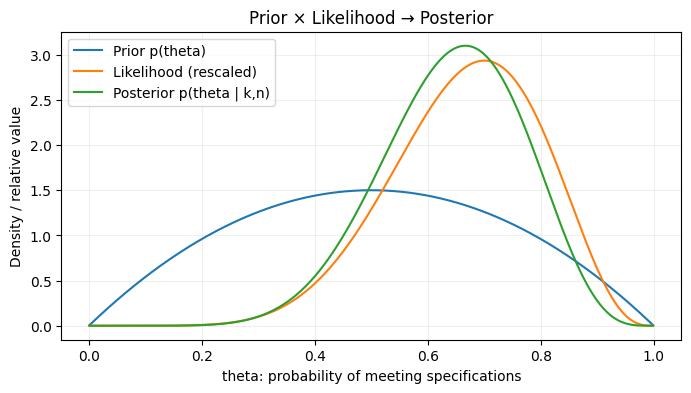

In [ ]:
grid = np.linspace(0.001, 0.999, 500)
prior_pdf = beta_dist.pdf(grid, alpha, beta)
posterior_pdf = beta_dist.pdf(grid, alpha_post, beta_post)
likelihood = comb(n,k) * grid**k * (1-grid)**(n-k)
likelihood_rescaled = likelihood / trapezoid(likelihood, grid)

plt.figure(figsize=(8,4))
plt.plot(grid, prior_pdf, label='Prior p(theta)')
plt.plot(grid, likelihood_rescaled, label='Likelihood (rescaled)')
plt.plot(grid, posterior_pdf, label='Posterior p(theta | k,n)')
plt.xlabel('theta: probability of meeting specifications')
plt.ylabel('Density / relative value')
plt.title('Prior × Likelihood → Posterior')
plt.legend()
plt.grid(alpha=0.2)
plt.show()

### 4.2 Posterior predictive — Predicting the next part

$$
P(Y_{n+1}=1\mid \mathcal D)
=\int_0^1 P(Y_{n+1}=1\mid \theta)p(\theta\mid\mathcal D)\,d\theta
=\mathbb E[\theta\mid\mathcal D].
$$

Here, we *marginalize* over the remaining uncertainty about $\theta$.


In [ ]:
predictive = alpha_post/(alpha_post+beta_post)
monte_carlo_thetas = rng.beta(alpha_post, beta_post, size=100_000)
mc_predictive = monte_carlo_thetas.mean()
print(f'Analytical prediction: {predictive:.4f}')
print(f'Monte Carlo prediction: {mc_predictive:.4f}')
assert abs(predictive-mc_predictive) < 0.01

**Exercise 3.** Choose a $\operatorname{Beta}(1,1)$ prior, then observe 2 successes and 8 failures. What is the posterior distribution? What is the predictive probability that the next outcome is a success?


In [ ]:
# EXERCISE 3
# a0, b0 = 1, 1
# successes, failures = 2, 8
# a1, b1 = ..., ...
# print('Posterior :', (a1,b1), 'Predictive :', a1/(a1+b1))

## 5. A small continuous inverse problem — Gaussian observation

A hidden property $Z$ follows $\mathcal N(0,1)$. A sensor returns

$$
Y=Z+\varepsilon,\qquad\varepsilon\sim\mathcal N(0,0.5^2).
$$

We observe $y=1.2$. The posterior over $z$ is Gaussian:

$$
\sigma^2_{\rm post}=\left(\frac1{\sigma_0^2}+\frac1{\sigma_\varepsilon^2}\right)^{-1},\qquad
\mu_{\rm post}=\sigma^2_{\rm post}\left(\frac{\mu_0}{\sigma_0^2}+\frac{y}{\sigma_\varepsilon^2}\right).
$$

The evidence can also be computed: $p(y)=\mathcal N(y;\mu_0,\sigma_0^2+\sigma_\varepsilon^2)$.


Posterior Z|Y : N(0.960, 0.200) [variance]
Analytical evidence: 0.200586
Evidence by integration: 0.200586


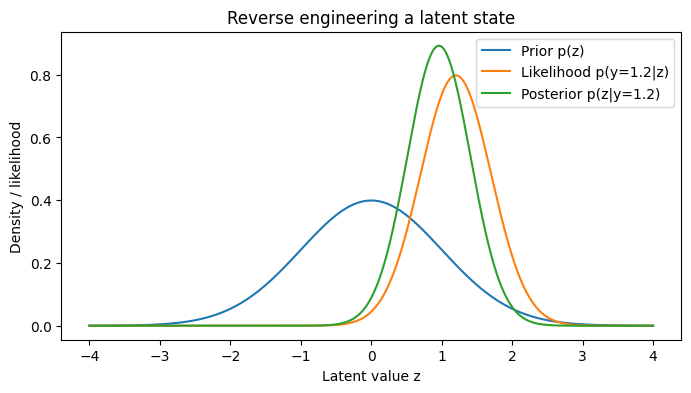

In [ ]:
mu0, sigma0 = 0.0, 1.0
sigma_eps, y_obs = 0.5, 1.2
var_post = 1/(1/sigma0**2 + 1/sigma_eps**2)
mu_post = var_post*(mu0/sigma0**2 + y_obs/sigma_eps**2)
evidence_y = norm.pdf(y_obs, loc=mu0, scale=np.sqrt(sigma0**2+sigma_eps**2))

z_grid = np.linspace(-4, 4, 4001)
prior_z = norm.pdf(z_grid, mu0, sigma0)
like_y_given_z = norm.pdf(y_obs, loc=z_grid, scale=sigma_eps)
posterior_z = norm.pdf(z_grid, mu_post, np.sqrt(var_post))
evidence_numerical = trapezoid(prior_z*like_y_given_z, z_grid)

print(f'Posterior Z|Y : N({mu_post:.3f}, {var_post:.3f}) [variance]')
print(f'Analytical evidence: {evidence_y:.6f}')
print(f'Evidence by integration: {evidence_numerical:.6f}')
assert np.isclose(evidence_y, evidence_numerical, rtol=1e-5)

plt.figure(figsize=(8,4))
plt.plot(z_grid, prior_z, label='Prior p(z)')
plt.plot(z_grid, like_y_given_z, label='Likelihood p(y=1.2|z)')
plt.plot(z_grid, posterior_z, label='Posterior p(z|y=1.2)')
plt.xlabel('Latent value z')
plt.ylabel('Density / likelihood')
plt.title('Reverse engineering a latent state')
plt.legend()
plt.show()

## 6. Quick assessment (without looking at the solutions)

1. In Bayes' theorem, which term ensures that posterior probabilities sum to 1?
2. In the A/B/C fault example, can we directly compare likelihoods to obtain the posterior? Why?
3. What is the difference between $p(y\mid\theta)$ and $p(\theta\mid y)$?
4. How do we compute $p(y)$ when $\theta$ is continuous?
5. In a VAE, what do the prior $p(z)$, decoder $p_\theta(x\mid z)$, and posterior $p_\theta(z\mid x)$ represent?

**Mini-project.** Change the base rate in the quality-control example and explain in one paragraph how the posterior changes. You may illustrate your explanation with a plot.


## 7. Guided solutions and self-checks

<details><summary><b>Show solutions to exercises 1–3</b></summary>

**Exercise 1.** $P(+)=0.9\times0.01+0.05\times0.99=0.0585$, and $P(D\mid+)=0.009/0.0585\approx 15.38\%$.

**Exercise 2.** $P(H_k\mid +,+)\propto P(H_k)P(+\mid H_k)^2$.

**Exercise 3.** Posterior $\operatorname{Beta}(3,9)$, predictive probability $3/(3+9)=0.25$.

</details>


In [ ]:
# Numerical solutions for checking (self-contained)
ex1_evidence, ex1_posterior = bayes_binary(0.01, 0.90, 0.95)
ex2_post, _ = update_discrete(prior, likelihood_alarm**2)
ex3_posterior_params = (1+2, 1+8)

print(f'Ex.1 : evidence={ex1_evidence:.4f}, posterior={ex1_posterior:.4f}')
print('Ex.2 : posterior after two alarms =', np.round(ex2_post, 4))
print('Ex.3 : Beta', ex3_posterior_params, ', predictive probability =',
      ex3_posterior_params[0]/sum(ex3_posterior_params))
assert np.isclose(ex1_posterior, 0.009/0.0585)
assert np.isclose(ex3_posterior_params[0]/sum(ex3_posterior_params), 0.25)

## 8. Key takeaways — A bridge to generative models

$$
\boxed{\underbrace{p(z)}_{\rm prior}\ \underbrace{p(x\mid z)}_{\rm likelihood}
\xrightarrow{\rm normalization}\underbrace{p(z\mid x)}_{\rm posterior}}.
$$

- **Forward:** $z\to x$, simulate an observation.
- **Inverse:** $x\to z$, infer the latent cause.
- **Marginal:** $p(x)=\int p(x\mid z)p(z)\,dz$.
- **VAE:** when this marginal is difficult to compute, we learn an approximate posterior $q_\phi(z\mid x)$ and optimize a variational bound.


**Reproduce this article of applied VAE** :https://towardsdatascience.com/vae-for-time-series-1dc0fef4bffa/

**Plz Pay attention to this article**: https://towardsdatascience.com/variational-autoencoders-vaes-explained-from-theory-to-elbo-and-the-reparameterization-trick/